In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, warnings
warnings.filterwarnings('ignore', category=RuntimeWarning)   # empty slices where a whole row was dropped
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score

DATA = '../data'
X_train = np.load(f'{DATA}/train_cadences.npy', mmap_mode='r')   # (18000, 6, 16, 128) uint8
X_test  = np.load(f'{DATA}/test_cadences.npy', mmap_mode='r')    # (10000, 6, 16, 128) uint8
train = pd.read_csv(f'{DATA}/train_meta.csv')
test  = pd.read_csv(f'{DATA}/test_meta.csv')
print(X_train.shape, X_test.shape)
print(train.label.value_counts().to_dict())

(18000, 6, 16, 128) (10000, 6, 16, 128)
{'noise': 4211, 'rfi_persistent': 2892, 'rfi_intermittent': 2662, 'radar_chirp': 1849, 'satellite_pass': 1805, 'pulsar': 1629, 'scintillating_star': 1431, 'frb': 1042, 'eti_candidate': 479}


In [2]:
import numpy as np
import pandas as pd
import torch
import sklearn

print("PyTorch:", torch.__version__)
print("Scikit-learn:", sklearn.__version__)
print("Device:", "CUDA GPU" if torch.cuda.is_available() else "CPU")

print("Raw training data:", X_train.shape)
print("Raw test data:", X_test.shape)
print("Labels:", train["label"].nunique())
print(train["label"].value_counts())

PyTorch: 2.14.1+cpu
Scikit-learn: 1.9.1
Device: CPU
Raw training data: (18000, 6, 16, 128)
Raw test data: (10000, 6, 16, 128)
Labels: 9
label
noise                 4211
rfi_persistent        2892
rfi_intermittent      2662
radar_chirp           1849
satellite_pass        1805
pulsar                1629
scintillating_star    1431
frb                   1042
eti_candidate          479
Name: count, dtype: int64


In [3]:
def prepare_cnn_input(X):
    X = np.asarray(X, dtype=np.float32)

    # Zero-valued pixels are missing.
    mask = X != 0

    # Normalize each sample and panel independently.
    valid_count = mask.sum(axis=(2, 3), keepdims=True)
    safe_count = np.maximum(valid_count, 1)

    observed = np.where(mask, X, 0.0)
    mean = observed.sum(axis=(2, 3), keepdims=True) / safe_count

    centered = np.where(mask, X - mean, 0.0)
    variance = (centered ** 2).sum(
        axis=(2, 3), keepdims=True
    ) / safe_count

    std = np.sqrt(variance)
    std = np.maximum(std, 1.0)

    normalized = np.where(mask, centered / std, 0.0)

    # CNN input: 6 normalized signal channels + 6 missingness masks.
    result = np.concatenate(
        [normalized, mask.astype(np.float32)],
        axis=1,
    )

    return result.astype(np.float32)


X_cnn = prepare_cnn_input(X_train)
X_cnn_test = prepare_cnn_input(X_test)

print("CNN training input:", X_cnn.shape)
print("CNN test input:", X_cnn_test.shape)

assert X_cnn.shape == (18000, 12, 16, 128)
assert X_cnn_test.shape == (10000, 12, 16, 128)

CNN training input: (18000, 12, 16, 128)
CNN test input: (10000, 12, 16, 128)


In [5]:
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

# Recreate label encoding consistently.
label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(train["label"])

# Recreate the same stratified split.
indices = np.arange(len(y_encoded))

train_idx, val_idx = train_test_split(
    indices,
    test_size=0.2,
    stratify=y_encoded,
    random_state=42
)

print("Classes:", list(label_encoder.classes_))
print("Training samples:", len(train_idx))
print("Validation samples:", len(val_idx))

Classes: ['eti_candidate', 'frb', 'noise', 'pulsar', 'radar_chirp', 'rfi_intermittent', 'rfi_persistent', 'satellite_pass', 'scintillating_star']
Training samples: 14400
Validation samples: 3600


In [6]:
# Reuse your original E5 preprocessing.
# Do not use prepare_cnn_input_e7 or prepare_cnn_input_e8 here.

X_train_split_e9 = prepare_cnn_input(X_train[train_idx])
X_val_e9 = prepare_cnn_input(X_train[val_idx])

print("Training:", X_train_split_e9.shape)
print("Validation:", X_val_e9.shape)

assert X_train_split_e9.shape == (14400, 12, 16, 128)
assert X_val_e9.shape == (3600, 12, 16, 128)

Training: (14400, 12, 16, 128)
Validation: (3600, 12, 16, 128)


In [7]:
import torch
import torch.nn as nn

class SignalCNN_E9(nn.Module):
    def __init__(self, num_classes=9):
        super().__init__()

        # Shared across all six panels.
        self.panel_encoder = nn.Sequential(
            nn.Conv2d(2, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.AdaptiveAvgPool2d((2, 8))
        )

        # 128 * 2 * 8 = 2048 features per panel.
        self.classifier = nn.Sequential(
            nn.Linear(2048 * 4, 256),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(256, num_classes)
        )

    def forward(self, x):
        # x: (B, 12, 16, 128)
        signal = x[:, :6]
        mask = x[:, 6:]

        # Encode each panel independently with shared weights.
        panel_features = []

        for p in range(6):
            panel = torch.stack(
                [signal[:, p], mask[:, p]],
                dim=1
            )
            encoded = self.panel_encoder(panel)
            encoded = torch.flatten(encoded, start_dim=1)
            panel_features.append(encoded)

        # Panel order: ON, OFF, ON, OFF, ON, OFF.
        on_features = torch.stack(
            [panel_features[0], panel_features[2], panel_features[4]],
            dim=1
        ).mean(dim=1)

        off_features = torch.stack(
            [panel_features[1], panel_features[3], panel_features[5]],
            dim=1
        ).mean(dim=1)

        combined = torch.cat(
            [
                on_features,
                off_features,
                on_features - off_features,
                torch.abs(on_features - off_features)
            ],
            dim=1
        )

        return self.classifier(combined)

In [8]:
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

model_e9 = SignalCNN_E9(
    num_classes=len(label_encoder.classes_)
).to(device)

dummy = torch.zeros(2, 12, 16, 128, device=device)

with torch.no_grad():
    output = model_e9(dummy)

print("Device:", device)
print("Output shape:", output.shape)
print("Parameters:", sum(p.numel() for p in model_e9.parameters()))

assert output.shape == (2, len(label_encoder.classes_))

Device: cpu
Output shape: torch.Size([2, 9])
Parameters: 2193129


In [9]:
import torch
import numpy as np
from torch.utils.data import TensorDataset, DataLoader

X_train_tensor_e9 = torch.from_numpy(
    np.ascontiguousarray(X_train_split_e9)
).float()

X_val_tensor_e9 = torch.from_numpy(
    np.ascontiguousarray(X_val_e9)
).float()

y_train_tensor_e9 = torch.tensor(
    y_encoded[train_idx], dtype=torch.long
)

y_val_tensor_e9 = torch.tensor(
    y_encoded[val_idx], dtype=torch.long
)

train_loader_e9 = DataLoader(
    TensorDataset(X_train_tensor_e9, y_train_tensor_e9),
    batch_size=64,
    shuffle=True,
    num_workers=0
)

val_loader_e9 = DataLoader(
    TensorDataset(X_val_tensor_e9, y_val_tensor_e9),
    batch_size=128,
    shuffle=False,
    num_workers=0
)

print("Training batches:", len(train_loader_e9))
print("Validation batches:", len(val_loader_e9))

Training batches: 225
Validation batches: 29


In [10]:
import torch.nn as nn
import copy
import random
from sklearn.metrics import f1_score

random.seed(42)
np.random.seed(42)
torch.manual_seed(42)

num_classes = len(label_encoder.classes_)

class_counts = np.bincount(
    y_encoded[train_idx],
    minlength=num_classes
)

class_weights_e9 = 1.0 / np.sqrt(class_counts)
class_weights_e9 /= class_weights_e9.mean()

criterion_e9 = nn.CrossEntropyLoss(
    weight=torch.tensor(
        class_weights_e9,
        dtype=torch.float32,
        device=device
    )
)

optimizer_e9 = torch.optim.AdamW(
    model_e9.parameters(),
    lr=1e-3,
    weight_decay=1e-4
)

print("Class weights:", class_weights_e9)

Class weights: [1.80341627 1.22284911 0.6080578  0.97773951 0.9177223  0.7647255
 0.73369185 0.92877769 1.04301998]


In [11]:
best_f1_e9 = -1.0
best_state_e9 = None
patience_e9 = 4
no_improve_e9 = 0
max_epochs_e9 = 20

for epoch in range(max_epochs_e9):
    model_e9.train()
    total_loss = 0.0
    total_samples = 0

    for xb, yb in train_loader_e9:
        xb = xb.to(device)
        yb = yb.to(device)

        optimizer_e9.zero_grad(set_to_none=True)

        logits = model_e9(xb)
        loss = criterion_e9(logits, yb)

        loss.backward()
        optimizer_e9.step()

        total_loss += loss.item() * len(yb)
        total_samples += len(yb)

    model_e9.eval()
    val_true_e9 = []
    val_pred_e9 = []

    with torch.no_grad():
        for xb, yb in val_loader_e9:
            xb = xb.to(device)

            logits = model_e9(xb)
            preds = logits.argmax(dim=1).cpu().numpy()

            val_pred_e9.extend(preds)
            val_true_e9.extend(yb.numpy())

    val_f1_e9 = f1_score(
        val_true_e9,
        val_pred_e9,
        average="macro",
        zero_division=0
    )

    train_loss_e9 = total_loss / total_samples

    print(
        f"Epoch {epoch + 1:02d}/{max_epochs_e9} | "
        f"Train loss: {train_loss_e9:.4f} | "
        f"Val macro-F1: {val_f1_e9:.4f}"
    )

    if val_f1_e9 > best_f1_e9:
        best_f1_e9 = val_f1_e9
        best_state_e9 = copy.deepcopy(model_e9.state_dict())
        no_improve_e9 = 0
        torch.save(best_state_e9, "e9_best.pt")
        print("  Best checkpoint saved.")
    else:
        no_improve_e9 += 1

    if no_improve_e9 >= patience_e9:
        print("Early stopping.")
        break

model_e9.load_state_dict(best_state_e9)

print(f"\nBest E9 validation macro-F1: {best_f1_e9:.4f}")

Epoch 01/20 | Train loss: 1.2376 | Val macro-F1: 0.6112
  Best checkpoint saved.
Epoch 02/20 | Train loss: 0.8332 | Val macro-F1: 0.6918
  Best checkpoint saved.
Epoch 03/20 | Train loss: 0.7344 | Val macro-F1: 0.6936
  Best checkpoint saved.
Epoch 04/20 | Train loss: 0.6584 | Val macro-F1: 0.4586
Epoch 05/20 | Train loss: 0.6068 | Val macro-F1: 0.7157
  Best checkpoint saved.
Epoch 06/20 | Train loss: 0.5503 | Val macro-F1: 0.7321
  Best checkpoint saved.
Epoch 07/20 | Train loss: 0.5106 | Val macro-F1: 0.7481
  Best checkpoint saved.
Epoch 08/20 | Train loss: 0.4608 | Val macro-F1: 0.7495
  Best checkpoint saved.
Epoch 09/20 | Train loss: 0.4319 | Val macro-F1: 0.7406
Epoch 10/20 | Train loss: 0.3894 | Val macro-F1: 0.7526
  Best checkpoint saved.
Epoch 11/20 | Train loss: 0.3620 | Val macro-F1: 0.7231
Epoch 12/20 | Train loss: 0.3234 | Val macro-F1: 0.7675
  Best checkpoint saved.
Epoch 13/20 | Train loss: 0.2811 | Val macro-F1: 0.7413
Epoch 14/20 | Train loss: 0.2617 | Val macro-F1

In [12]:
import torch
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix, f1_score

# Restore the best checkpoint.
state = torch.load("e9_best.pt", map_location=device, weights_only=True)
model_e9.load_state_dict(state)
model_e9.eval()

val_true_e9 = []
val_pred_e9 = []

with torch.no_grad():
    for xb, yb in val_loader_e9:
        xb = xb.to(device)
        logits = model_e9(xb)

        val_pred_e9.extend(logits.argmax(dim=1).cpu().numpy())
        val_true_e9.extend(yb.numpy())

print("Best checkpoint macro-F1:",
      f1_score(val_true_e9, val_pred_e9,
               average="macro", zero_division=0))

print(classification_report(
    val_true_e9,
    val_pred_e9,
    labels=np.arange(len(label_encoder.classes_)),
    target_names=label_encoder.classes_,
    digits=3,
    zero_division=0
))

Best checkpoint macro-F1: 0.7674531245281944
                    precision    recall  f1-score   support

     eti_candidate      0.373     0.260     0.307        96
               frb      0.859     0.933     0.894       209
             noise      0.878     0.867     0.873       842
            pulsar      0.902     0.991     0.944       326
       radar_chirp      0.885     0.957     0.919       370
  rfi_intermittent      0.767     0.742     0.755       532
    rfi_persistent      0.833     0.881     0.856       578
    satellite_pass      0.780     0.837     0.807       361
scintillating_star      0.662     0.472     0.551       286

          accuracy                          0.824      3600
         macro avg      0.771     0.771     0.767      3600
      weighted avg      0.816     0.824     0.818      3600



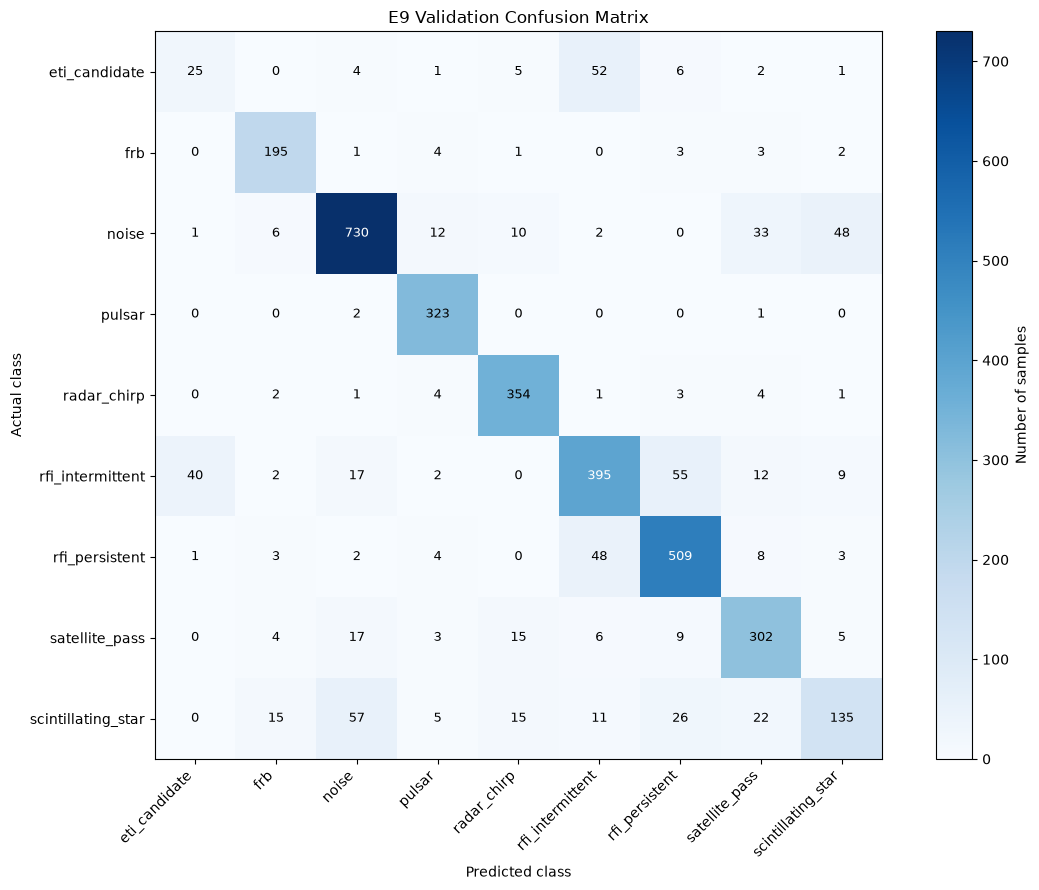

In [14]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import confusion_matrix

class_names = [
    "eti_candidate",
    "frb",
    "noise",
    "pulsar",
    "radar_chirp",
    "rfi_intermittent",
    "rfi_persistent",
    "satellite_pass",
    "scintillating_star",
]

cm = confusion_matrix(
    val_true_e9,
    val_pred_e9,
    labels=np.arange(len(class_names))
)

fig, ax = plt.subplots(figsize=(12, 9))

image = ax.imshow(cm, interpolation="nearest", cmap="Blues")
fig.colorbar(image, ax=ax, label="Number of samples")

ax.set(
    xticks=np.arange(len(class_names)),
    yticks=np.arange(len(class_names)),
    xticklabels=class_names,
    yticklabels=class_names,
    xlabel="Predicted class",
    ylabel="Actual class",
    title="E9 Validation Confusion Matrix"
)

plt.setp(ax.get_xticklabels(), rotation=45, ha="right")

# Annotate each cell with its count
threshold = cm.max() / 2

for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        ax.text(
            j, i, str(cm[i, j]),
            ha="center",
            va="center",
            color="white" if cm[i, j] > threshold else "black",
            fontsize=9
        )

fig.tight_layout()
plt.show()

In [21]:
import pandas as pd
import numpy as np
import os

# Load the official test metadata
test_meta = pd.read_csv("../data/test_meta.csv")

# Verify predictions align with test rows
assert len(predicted_labels) == len(test_meta), (
    f"Prediction count: {len(predicted_labels)}, "
    f"test rows: {len(test_meta)}"
)

# Build submission using the actual competition IDs
submission_e9 = pd.DataFrame({
    "id": test_meta["id"].values,
    "label": predicted_labels
})

# Validate the submission
assert submission_e9["id"].equals(test_meta["id"])
assert submission_e9["id"].is_unique
assert submission_e9["label"].notna().all()
assert len(submission_e9) == 10000

# Save to the submissions directory
os.makedirs("../outputs/submissions", exist_ok=True)

output_path = "../outputs/submissions/submission_e9.csv"
submission_e9.to_csv(output_path, index=False)

print("Saved:", output_path)
print("Shape:", submission_e9.shape)
print("\nPreview:")
print(submission_e9.head())

print("\nPrediction distribution:")
print(submission_e9["label"].value_counts())

print("\nColumns:", submission_e9.columns.tolist())

Saved: ../outputs/submissions/submission_e9.csv
Shape: (10000, 2)

Preview:
           id             label
0  SX8206356f             noise
1  SXa38c75e1  rfi_intermittent
2  SX8d18396a            pulsar
3  SXd33cd81f               frb
4  SX339a8091               frb

Prediction distribution:
label
scintillating_star    3750
rfi_intermittent      1745
frb                   1081
pulsar                 975
rfi_persistent         970
satellite_pass         694
radar_chirp            625
eti_candidate          122
noise                   38
Name: count, dtype: int64

Columns: ['id', 'label']


In [16]:
import os

for root, dirs, files in os.walk("../data"):
    for file in files:
        print(os.path.join(root, file))

../data\test_cadences.npy
../data\test_meta.csv
../data\train_cadences.npy
../data\train_meta.csv


In [19]:
import pandas as pd

train_meta = pd.read_csv("../data/train_meta.csv")
test_meta = pd.read_csv("../data/test_meta.csv")

print("TRAIN METADATA")
print("Shape:", train_meta.shape)
print("Columns:", train_meta.columns.tolist())
print(train_meta.head())

print("\nTEST METADATA")
print("Shape:", test_meta.shape)
print("Columns:", test_meta.columns.tolist())
print(test_meta.head())

TRAIN METADATA
Shape: (18000, 8)
Columns: ['id', 'telescope', 'target', 'center_freq_mhz', 'channel_width_hz', 'tsamp_s', 'slew_gap_rows', 'label']
           id telescope    target  center_freq_mhz  channel_width_hz  tsamp_s  \
0  SH7cefe0e1       GBT  HIP59624      1384.518387              2.79    18.25   
1  SH1dbf97aa       GBT  HIP27609      1659.448768              2.79    18.25   
2  SHc19f6060       GBT  HIP45387      1627.507811              2.79    18.25   
3  SH41a0663c       GBT  HIP67753      1107.781667              2.79    18.25   
4  SHdb4c65a1       GBT  HIP93142      1507.034261              2.79    18.25   

   slew_gap_rows               label  
0              5  scintillating_star  
1              6      satellite_pass  
2              3      rfi_persistent  
3              5    rfi_intermittent  
4              4              pulsar  

TEST METADATA
Shape: (10000, 7)
Columns: ['id', 'telescope', 'target', 'center_freq_mhz', 'channel_width_hz', 'tsamp_s', 'slew_gap

In [20]:
print("Test metadata columns:", test_meta.columns.tolist())

for col in test_meta.columns:
    print(f"\n{col}:")
    print(test_meta[col].head(10).tolist())

Test metadata columns: ['id', 'telescope', 'target', 'center_freq_mhz', 'channel_width_hz', 'tsamp_s', 'slew_gap_rows']

id:
['SX8206356f', 'SXa38c75e1', 'SX8d18396a', 'SXd33cd81f', 'SX339a8091', 'SX91bf74c0', 'SXab41203a', 'SXde8381e0', 'SXdb45300e', 'SX51ede4cb']

telescope:
['PKS', 'PKS', 'PKS', 'PKS', 'PKS', 'PKS', 'PKS', 'PKS', 'PKS', 'PKS']

target:
['HIP34349', 'HIP71150', 'HIP88416', 'HIP108837', 'HIP39544', 'HIP73628', 'HIP61265', 'HIP86936', 'HIP4645', 'HIP47060']

center_freq_mhz:
[1459.783916, 1306.265649, 1203.137374, 1464.879689, 1433.860149, 1379.075096, 1246.078104, 1335.738624, 1475.074221, 1299.327908]

channel_width_hz:
[3.81, 3.81, 3.81, 3.81, 3.81, 3.81, 3.81, 3.81, 3.81, 3.81]

tsamp_s:
[16.0, 16.0, 16.0, 16.0, 16.0, 16.0, 16.0, 16.0, 16.0, 16.0]

slew_gap_rows:
[5, 4, 4, 3, 5, 5, 4, 6, 4, 3]
